# Analisi della sessione 18:00–00:00

Requisiti nell'ambiente virtuale: `pip install pandas pyarrow matplotlib ipykernel`.
Il notebook va messo nella cartella `analisi`, accanto alla cartella `dati` e al file `q1_progress.log`.

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (12, 4)
FUSO = "Europe/Rome"

def asse_orario(ax):
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=FUSO))
    ax.grid(alpha=0.3)

## 1. Caricamento

Elasticsearch non restituisce i documenti in ordine, quindi la serie va ordinata per `window_start` prima di qualsiasi analisi.

In [2]:
serie = (pd.read_parquet("dati/sentiment_1m.parquet")
           .sort_values("window_start")
           .reset_index(drop=True))
posts = pd.read_parquet("dati/posts.parquet")
try:
    alerts = pd.read_parquet("dati/alerts.parquet")
except FileNotFoundError:
    alerts = pd.DataFrame()   # nessun episodio nella sessione

print(f"Finestre: {len(serie)}   Post: {len(posts):,}   Alert: {len(alerts)}")
print("Dal", serie.window_start.min().tz_convert(FUSO), "al", serie.window_start.max().tz_convert(FUSO))
print("Modelli:", serie.model.unique())

Finestre: 350   Post: 626,109   Alert: 0
Dal 2026-11-08 17:57:00+01:00 al 2026-11-08 23:46:00+01:00
Modelli: <ArrowStringArray>
['cardiffnlp/twitter-roberta-base-sentiment-latest+ov:fp32@GPU']
Length: 1, dtype: str


## 2. Velocità di Q1 dentro Spark

Nel log `in` è la velocità con cui arrivavano i post, `elab` quella con cui Q1 li ha elaborati (righe diviso durata del batch).
Se `elab` resta sopra `in`, Q1 tiene il passo. Escludo i primi due batch: il primo è vuoto e il secondo include la compilazione dei kernel della GPU.

In [4]:
schema = re.compile(r"batch=(\d+) righe=(\d+) in=([\d.]+)/s elab=([\d.]+)/s addBatch=(\d+)ms totale=(\d+)ms")
righe_log = []
with open("dati/q1_progress.log") as f:
    for riga in f:
        m = schema.search(riga)
        if m:
            righe_log.append([float(x) for x in m.groups()])

q1 = pd.DataFrame(righe_log, columns=["batch", "righe", "in_s", "elab_s", "addbatch_ms", "totale_ms"])
q1 = q1.drop_duplicates("batch").sort_values("batch")
q1r = q1[(q1.batch >= 2) & (q1.righe > 0)].copy()
q1r["durata_s"] = q1r.totale_ms / 1000

print(f"Batch analizzati: {len(q1r)}")
print(f"Post elaborati in totale: {q1r.righe.sum():,.0f}")
print(f"Velocità di elaborazione: mediana {q1r.elab_s.median():.1f}/s, media {q1r.elab_s.mean():.1f}/s")
print(f"Velocità di arrivo:      mediana {q1r.in_s.median():.1f}/s, massimo {q1r.in_s.max():.1f}/s")
print(f"Batch in cui Q1 era più lento degli arrivi: {(q1r.elab_s < q1r.in_s).mean():.1%}")
print(f"Durata dei batch: mediana {q1r.durata_s.median():.1f} s, massimo {q1r.durata_s.max():.1f} s")
print(f"Batch pieni (1500 righe, cioè recupero di arretrato): {(q1r.righe >= 1500).sum()}")

Batch analizzati: 2107
Post elaborati in totale: 624,686
Velocità di elaborazione: mediana 74.9/s, media 74.8/s
Velocità di arrivo:      mediana 29.5/s, massimo 100.1/s
Batch in cui Q1 era più lento degli arrivi: 0.1%
Durata dei batch: mediana 3.9 s, massimo 20.5 s
Batch pieni (1500 righe, cioè recupero di arretrato): 0


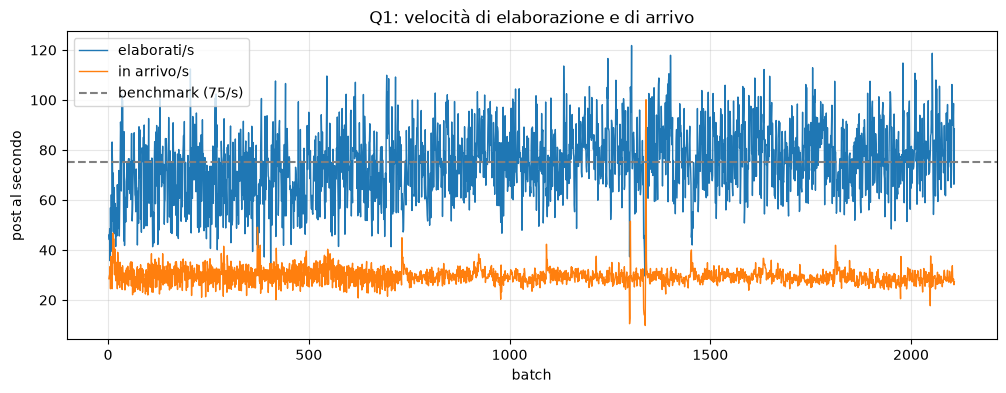

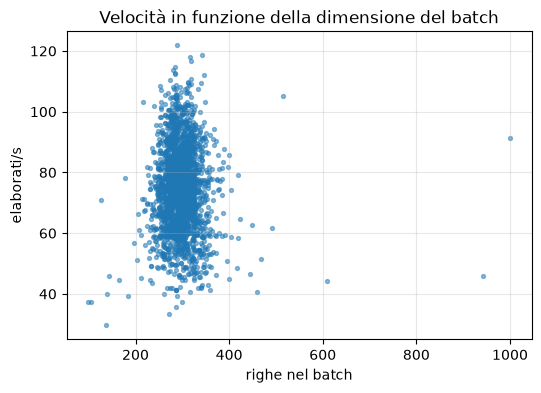

In [5]:
fig, ax = plt.subplots()
ax.plot(q1r.batch, q1r.elab_s, label="elaborati/s", lw=1)
ax.plot(q1r.batch, q1r.in_s, label="in arrivo/s", lw=1)
ax.axhline(75, ls="--", c="gray", label="benchmark (75/s)")
ax.set_xlabel("batch"); ax.set_ylabel("post al secondo"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Q1: velocità di elaborazione e di arrivo")
plt.show()

# Una parte del tempo di ogni batch è fissa (lettura da Kafka, scrittura, commit):
# per questo i batch piccoli hanno una velocità più bassa. Il grafico lo rende visibile.
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(q1r.righe, q1r.elab_s, s=8, alpha=0.5)
ax.set_xlabel("righe nel batch"); ax.set_ylabel("elaborati/s"); ax.grid(alpha=0.3)
ax.set_title("Velocità in funzione della dimensione del batch")
plt.show()

Stima del costo fisso per batch: se la durata è circa `fisso + righe / velocità_modello`, una retta sui dati separa le due parti.

In [6]:
import numpy as np
pend, intercetta = np.polyfit(q1r.righe, q1r.durata_s, 1)
print(f"Costo fisso per batch: circa {intercetta:.1f} s")
print(f"Velocità 'pura' del modello: circa {1/pend:.1f} post/s")

Costo fisso per batch: circa -0.6 s
Velocità 'pura' del modello: circa 62.2 post/s


## 3. Completezza della serie

Un minuto senza messaggio è un buco nell'ingestione, non un crollo del sentiment.

In [7]:
attesi = pd.date_range(serie.window_start.min(), serie.window_start.max(), freq="1min")
mancanti = attesi.difference(serie.window_start)
print(f"Minuti attesi: {len(attesi)}   presenti: {serie.window_start.nunique()}   mancanti: {len(mancanti)}")
print(f"Finestre duplicate: {serie.window_start.duplicated().sum()}")
if len(mancanti):
    print("Primi minuti mancanti (ora italiana):")
    print(pd.Series(mancanti.tz_convert(FUSO)).head(20).to_string(index=False))

Minuti attesi: 350   presenti: 350   mancanti: 0
Finestre duplicate: 0


## 4. Traffico

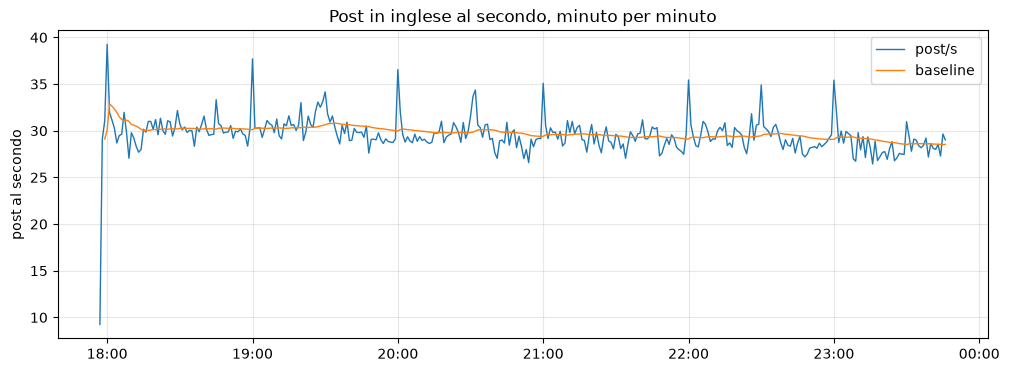

        mean   min   max
ora_it                  
17      23.1   9.2  31.1
18      30.2  27.0  39.2
19      30.4  27.6  37.7
20      29.6  26.6  36.6
21      29.3  27.0  35.1
22      29.4  27.2  35.4
23      28.5  26.4  35.4


In [8]:
serie["post_s"] = serie.n_posts / 60
fig, ax = plt.subplots()
ax.plot(serie.window_start, serie.post_s, lw=1, label="post/s")
if "baseline_volume" in serie:
    ax.plot(serie.window_start, serie.baseline_volume / 60, lw=1, label="baseline")
ax.set_ylabel("post al secondo"); ax.legend(); asse_orario(ax)
ax.set_title("Post in inglese al secondo, minuto per minuto")
plt.show()

serie["ora_it"] = serie.window_start.dt.tz_convert(FUSO).dt.hour
print(serie.groupby("ora_it").post_s.agg(["mean", "min", "max"]).round(1))

## 5. Qualità dei dati

Motivi di scarto delle finestre:
skip_reason
valida     349
startup      1

Finestre in warmup: 41
author_ratio: mediana 0.923, minimo 0.870
Finestre sotto r_min = 0,8: 0


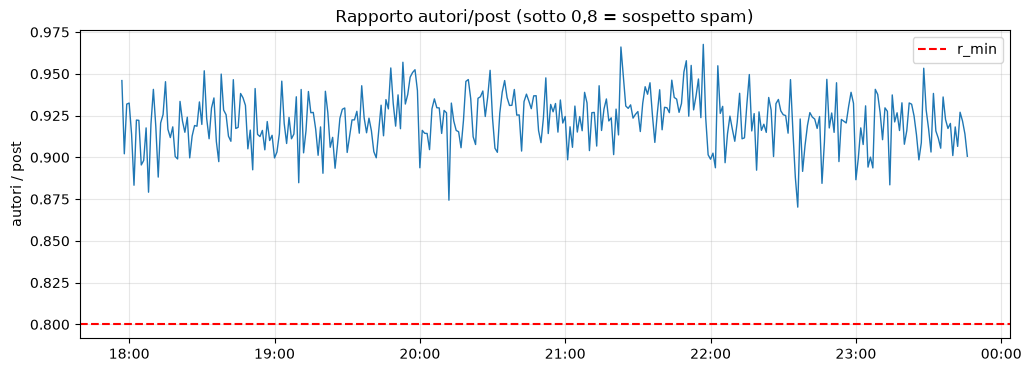

In [9]:
print("Motivi di scarto delle finestre:")
print(serie.skip_reason.fillna("valida").value_counts().to_string())
print(f"\nFinestre in warmup: {serie.warmup.sum()}")
print(f"author_ratio: mediana {serie.author_ratio.median():.3f}, minimo {serie.author_ratio.min():.3f}")
print(f"Finestre sotto r_min = 0,8: {(serie.author_ratio < 0.8).sum()}")

fig, ax = plt.subplots()
ax.plot(serie.window_start, serie.author_ratio, lw=1)
ax.axhline(0.8, ls="--", c="red", label="r_min")
ax.set_ylabel("autori / post"); ax.legend(); asse_orario(ax)
ax.set_title("Rapporto autori/post (sotto 0,8 = sospetto spam)")
plt.show()

## 6. Andamento del sentiment

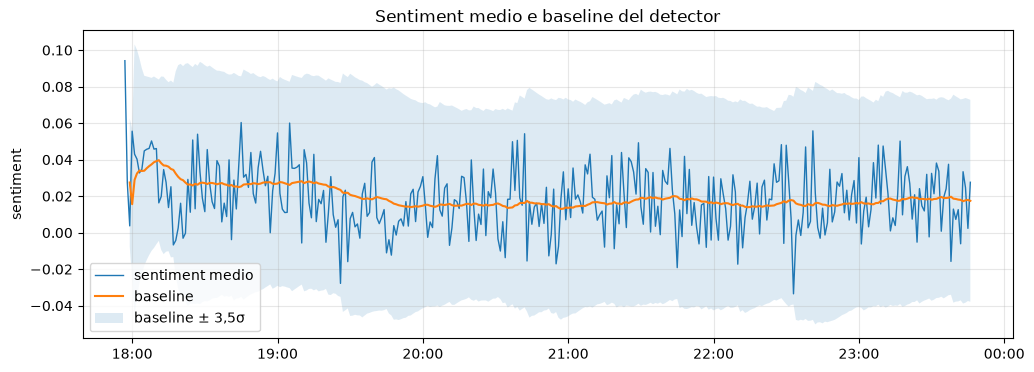

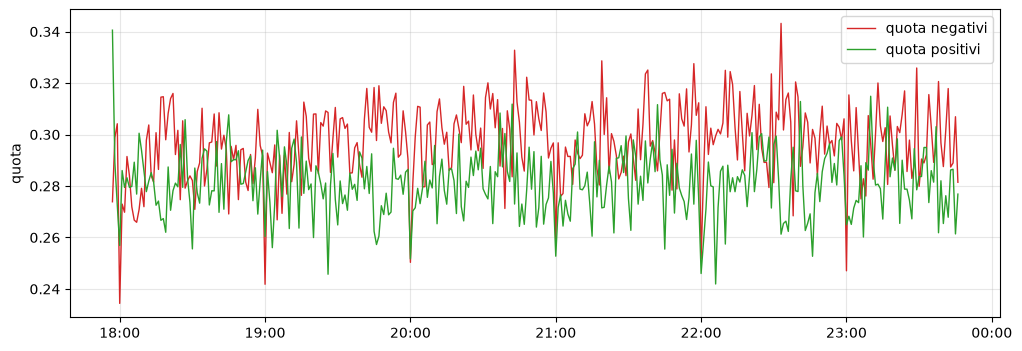

        mean_sentiment  share_negative  share_positive
ora_it                                                
17               0.042           0.292           0.301
18               0.027           0.289           0.282
19               0.015           0.297           0.279
20               0.014           0.301           0.281
21               0.019           0.298           0.281
22               0.015           0.301           0.281
23               0.019           0.296           0.281


In [10]:
fig, ax = plt.subplots()
ax.plot(serie.window_start, serie.mean_sentiment, lw=1, label="sentiment medio")
ax.plot(serie.window_start, serie.baseline_mean, lw=1.5, label="baseline")
banda = 3.5 * serie.baseline_std
ax.fill_between(serie.window_start, serie.baseline_mean - banda, serie.baseline_mean + banda,
                alpha=0.15, label="baseline ± 3,5σ")
ax.set_ylabel("sentiment"); ax.legend(); asse_orario(ax)
ax.set_title("Sentiment medio e baseline del detector")
plt.show()

fig, ax = plt.subplots()
ax.plot(serie.window_start, serie.share_negative, lw=1, label="quota negativi", c="tab:red")
ax.plot(serie.window_start, serie.share_positive, lw=1, label="quota positivi", c="tab:green")
ax.set_ylabel("quota"); ax.legend(); asse_orario(ax)
plt.show()

print(serie.groupby("ora_it")[["mean_sentiment", "share_negative", "share_positive"]].mean().round(3))

## 7. Il detector

Quante finestre supererebbero le soglie attuali (`k` = 3,5 e `k_low` = 2,5)? Contano solo le finestre attive: valide e fuori dal warmup.

Finestre attive: 309 su 350
z_sentiment: media -0.05, deviazione standard 1.02
  |z| > 2: 15 finestre
  |z| > 2.5: 2 finestre
  |z| > 3: 2 finestre
  |z| > 3.5: 0 finestre
  |z| > 4: 0 finestre
Finestre segnate come shock: 0   picchi di volume: 1


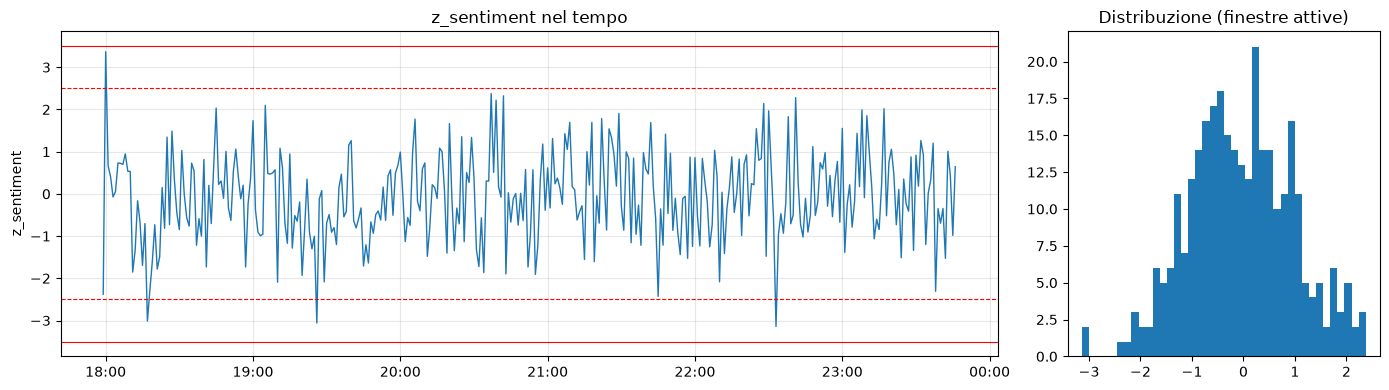

In [11]:
attive = serie[serie.skip_reason.isna() & ~serie.warmup & serie.z_sentiment.notna()]
z = attive.z_sentiment
print(f"Finestre attive: {len(attive)} su {len(serie)}")
print(f"z_sentiment: media {z.mean():.2f}, deviazione standard {z.std():.2f}")
for soglia in [2, 2.5, 3, 3.5, 4]:
    print(f"  |z| > {soglia}: {(z.abs() > soglia).sum()} finestre")
print(f"Finestre segnate come shock: {serie.is_shock.sum()}   picchi di volume: {serie.volume_spike.sum()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1]})
ax = axes[0]
ax.plot(serie.window_start, serie.z_sentiment, lw=1)
for s, stile in [(3.5, "-"), (2.5, "--")]:
    ax.axhline(s, c="red", ls=stile, lw=0.8); ax.axhline(-s, c="red", ls=stile, lw=0.8)
shock = serie[serie.is_shock]
ax.scatter(shock.window_start, shock.z_sentiment, c="red", zorder=3, label="shock")
ax.set_ylabel("z_sentiment"); asse_orario(ax); ax.set_title("z_sentiment nel tempo")
axes[1].hist(z, bins=40); axes[1].set_title("Distribuzione (finestre attive)")
plt.tight_layout(); plt.show()

Se la deviazione standard di `z_sentiment` è molto sopra 1, la baseline sottostima la variabilità e le soglie scattano troppo spesso; se è molto sotto 1, la sovrastima (spesso per colpa di `sigma_min_sentiment`).

In [12]:
if len(alerts):
    colonne = [c for c in ["alert_id", "status", "start", "end", "direction", "peak_z",
                           "n_shock_windows", "close_reason", "z_volume"] if c in alerts]
    display(alerts[colonne].sort_values("start"))
else:
    print("Nessun episodio nella sessione.")

Nessun episodio nella sessione.


## 8. I post

Post: 626,109   uri duplicati: 0   autori distinti: 172,416

Etichette:
sentiment_label
neutral     0.422
negative    0.297
positive    0.281

Risposte: 59.1%   citazioni: 10.0%   con link: 9.5%


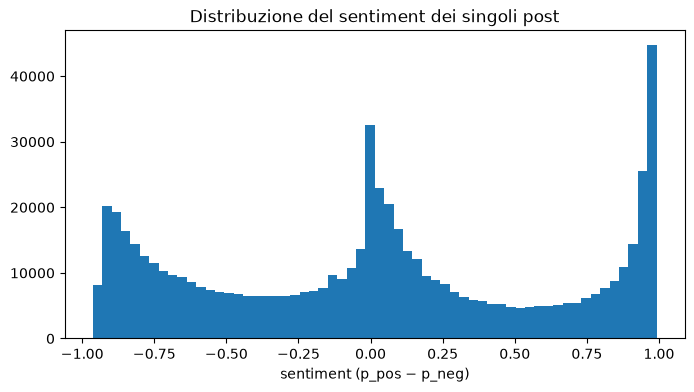

In [13]:
print(f"Post: {len(posts):,}   uri duplicati: {posts.uri.duplicated().sum()}   autori distinti: {posts.did.nunique():,}")
print("\nEtichette:")
print(posts.sentiment_label.value_counts(normalize=True).round(3).to_string())
print(f"\nRisposte: {posts.reply_parent_uri.notna().mean():.1%}   "
      f"citazioni: {posts.quoted_uri.notna().mean():.1%}   con link: {posts.link_title.notna().mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(posts.sentiment, bins=60)
ax.set_xlabel("sentiment (p_pos − p_neg)"); ax.set_title("Distribuzione del sentiment dei singoli post")
plt.show()

Controllo di coerenza tra Q1 e Q2: contando i post al minuto direttamente da `posts` dovrei ritrovare `n_posts` di Q2.
Differenze sistematiche indicherebbero post scartati dal watermark o persi tra le fasi.

In [14]:
conteggio = (posts.drop_duplicates("uri")
                  .assign(minuto=lambda d: d.time.dt.floor("1min"))
                  .groupby("minuto").size().rename("da_posts"))
confronto = serie.set_index("window_start")[["n_posts"]].join(conteggio, how="inner")
confronto["differenza"] = confronto.da_posts - confronto.n_posts
print(confronto.differenza.describe().round(2))
print(f"Minuti con differenza diversa da zero: {(confronto.differenza != 0).sum()} su {len(confronto)}")

count    350.00
mean      -0.00
std        0.05
min       -1.00
25%        0.00
50%        0.00
75%        0.00
max        0.00
Name: differenza, dtype: float64
Minuti con differenza diversa da zero: 1 su 350


In [15]:
print("Titoli di link più condivisi nella sessione:")
print(posts.link_title.dropna().value_counts().head(15).to_string())

Titoli di link più condivisi nella sessione:
link_title
→ zum Artikel                                                                        345
Instagram                                                                            199
Sign the Petition                                                                    181
Threads                                                                              169
Facebook                                                                             139
TikTok - Make Your Day                                                               100
Original post on mastodon.social                                                      86
MSN                                                                                   72
Trump Takes a DARK TURN & Expert WARNS What Comes NEXT...                             69
You Didn’t Vote Out Fascism. Believing You Did Is the Danger.                         68
🎯MapTap Daily Geography Game                          